# Frozen final confirmation: LightGBM and PyTorch

## Goal and execution

Compare five fixed systems on [2020-09-16, 2020-09-23), using the same
20,000 recipients and complete target reference sets.

Start a fresh kernel and **Run All**. No cells from notebook 08 need to run.
The default loads the already saved predictions. If evaluation is already
complete, verify and reload its recorded tables rather than recalculating it.

Inputs are the selected campaign, frozen model/preprocessing/vocabulary
artifacts, cohort, cached confirmation features and prepared H&M data.
These generated data are intentionally outside Git. Model architecture lives
in `src/atelier_ai/neural_ranker.py`; there is no notebook-source execution.

`REBUILD_PREDICTIONS=True` explicitly checks prediction reproduction against
the immutable saved lists. It never trains or replaces a different result.
Model choices remain those selected before confirmation.

In [1]:
import os
import sys

native_modules_loaded = any(
    name in sys.modules for name in ["torch", "lightgbm", "sklearn"]
)
if native_modules_loaded and (
    os.environ.get("OMP_NUM_THREADS") != "1"
    or os.environ.get("OMP_THREAD_LIMIT") != "1"
):
    raise RuntimeError("Restart this kernel, then Run All in notebook 09.")

# Set the OpenMP limits before importing numerical libraries on macOS.
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OMP_THREAD_LIMIT"] = "1"

import torch
torch.set_num_threads(1)
if torch.get_num_interop_threads() != 1:
    torch.set_num_interop_threads(1)

from pathlib import Path
from hashlib import sha256
import ast
import json
import numpy as np
import pandas as pd
import duckdb
import joblib
import lightgbm as lgb
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

import atelier_ai
import atelier_ai.neural_ranker as neural_ranker_module
from atelier_ai.neural_ranker import NeuralRanker, encode_ids
from atelier_ai.feature_export import file_sha256, verify_feature_export
from atelier_ai.recommendation_features import (
    FEATURE_COLUMNS, EXPECTED_MISSING_FEATURES, retrieve_candidates,
)
from atelier_ai.workflow import build_context, target_reference, evaluate_methods
from atelier_ai.pipeline_evaluate import paired_map_bootstrap

PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]
RUN_ID = "559f9ddac46f"
REBUILD_PREDICTIONS = False
FEATURE_EXPORT = "test_2020-09-16_fae8368dc524"
EXPECTED_PREDICTION_SHA256 = (
    "4460b950e38ef2434ef5302d800feb38375c6b736825d5fcf0bf39cb0aab9509"
)

run_directory = PROJECT_ROOT / "data/processed/pytorch_v1" / RUN_ID
confirmation_directory = run_directory / "confirmation"
comparison_protocol_path = confirmation_directory / "protocol.json"
prediction_path = confirmation_directory / "recommendations.json"
result_path = confirmation_directory / "manifest.json"
confirmation_spec = json.loads(comparison_protocol_path.read_text())

print("Frozen campaign:", RUN_ID)
print("Prediction mode:", "reproduce and compare" if REBUILD_PREDICTIONS else "load saved lists")
print("Evaluation mode:", "review saved results" if result_path.exists() else "first frozen evaluation")

Frozen campaign: 559f9ddac46f
Prediction mode: load saved lists
Evaluation mode: first frozen evaluation


## Verify frozen inputs

Preserve the declared fitting boundary, model identities, cohort and neural
architecture. A source change blocks a new calculation; recorded evaluation
results can still be reviewed using their artifact checksums.

In [2]:
assert confirmation_spec["status"] == "frozen_before_confirmation"
assert confirmation_spec["retune_after_confirmation"] is False
assert confirmation_spec["full_reference_targets"] is True
assert confirmation_spec["fitting_boundary_exclusive"] == "2020-09-09"
needs_calculation = REBUILD_PREDICTIONS or not result_path.exists()

source_changes = [
    relative_path
    for relative_path, digest in confirmation_spec["source_sha256"].items()
    if not (PROJECT_ROOT / relative_path).is_file()
    or file_sha256(PROJECT_ROOT / relative_path) != digest
]
if needs_calculation and source_changes:
    raise ValueError(f"Frozen calculation sources differ: {source_changes}")

frozen_refit_directory = PROJECT_ROOT / confirmation_spec["pytorch_refit_directory"]
assert file_sha256(frozen_refit_directory / "manifest.json") == confirmation_spec["pytorch_manifest_sha256"]
for name, digest in confirmation_spec["pytorch_files_sha256"].items():
    assert file_sha256(frozen_refit_directory / name) == digest, name

frozen_lightgbm_path = PROJECT_ROOT / confirmation_spec["lightgbm_model_file"]
assert file_sha256(frozen_lightgbm_path) == confirmation_spec["lightgbm_model_sha256"]
model_source = Path(neural_ranker_module.__file__).read_text()
class_sources = [
    ast.get_source_segment(model_source, node)
    for node in ast.parse(model_source).body
    if isinstance(node, ast.ClassDef) and node.name == "NeuralRanker"
]
assert len(class_sources) == 1
assert sha256(class_sources[0].encode()).hexdigest() == confirmation_spec["pytorch_class_sha256"]

cohort_path = PROJECT_ROOT / confirmation_spec["cohort_file"]
assert file_sha256(cohort_path) == confirmation_spec["cohort_file_sha256"]
confirmation_ids = pd.Index(
    pd.read_csv(cohort_path, dtype="string", keep_default_na=False)["customer_id"],
    dtype="string",
)
assert len(confirmation_ids) == confirmation_spec["recipients"] == 20_000
assert confirmation_ids.is_unique
assert sha256(("\n".join(confirmation_ids) + "\n").encode()).hexdigest() == confirmation_spec["cohort_sha256"]

confirmation_start = pd.Timestamp(confirmation_spec["start_inclusive"])
confirmation_end = pd.Timestamp(confirmation_spec["end_exclusive"])
assert confirmation_end - confirmation_start == pd.Timedelta(days=7)
if prediction_path.exists():
    assert file_sha256(prediction_path) == EXPECTED_PREDICTION_SHA256

confirmation_feature_directory = PROJECT_ROOT / "data/processed/weekly_v1/features" / FEATURE_EXPORT
confirmation_feature_manifest = json.loads(
    (confirmation_feature_directory / "manifest.json").read_text()
)
if needs_calculation:
    checks = verify_feature_export(confirmation_feature_directory)
    assert checks["rows"] == 6_000_000 and checks["customers"] == 20_000
    assert confirmation_feature_manifest["dataset_split"] == "test"
    assert pd.Timestamp(confirmation_feature_manifest["cutoff"]) == confirmation_start
    assert confirmation_feature_manifest["provenance"]["cohort_sha256"] == confirmation_spec["cohort_sha256"]
    assert confirmation_feature_manifest["feature_columns"] == FEATURE_COLUMNS
    assert "label" not in {item["name"] for item in confirmation_feature_manifest["schema"]}
    for key, value in confirmation_spec["retrieval"].items():
        assert confirmation_feature_manifest["provenance"][key] == value

confirmation_vocabularies = json.loads(
    (frozen_refit_directory / "vocabularies.json").read_text()
)
print("Frozen input identities verified.")

Frozen input identities verified.


## Reconstruct historical context when calculation is required

Rebuild in-memory candidate pools and reference lists from observations
strictly before the prediction cutoff. Reuse the cached feature export.
No feature dataset or model is regenerated.

In [3]:
if needs_calculation:
    confirmation_context = build_context(
        PROJECT_ROOT, confirmation_ids, confirmation_start
    )
    (
        confirmation_pools, memberships,
        confirmation_baseline_rows, confirmation_candidate_audit,
    ) = retrieve_candidates(confirmation_ids, confirmation_context)
    del memberships

    candidate_digest = sha256()
    for customer in confirmation_ids:
        payload = json.dumps(
            [str(customer), confirmation_pools[customer]],
            sort_keys=True, separators=(",", ":"), ensure_ascii=False,
        )
        candidate_digest.update((payload + "\n").encode())
    assert candidate_digest.hexdigest() == confirmation_feature_manifest["candidate_sha256"]

    dates = confirmation_context["history"]["t_dat"]
    assert dates.lt(confirmation_start).all()
    assert dates.ge(confirmation_start - pd.Timedelta(days=180)).all()
    print("Historical pools match the saved candidate export.")
else:
    print("Using completed evaluation; historical queries are skipped.")

Historical pools match the saved candidate export.


## Load saved predictions or explicitly verify prediction reproduction

Prediction reproduction loads frozen weights and preprocessing. It compares
its output with the existing immutable lists and does not overwrite a
different result. The default uses the lists already produced in notebook 08.

In [4]:
def reproduce_frozen_predictions():
    frozen_checkpoint = torch.load(
        frozen_refit_directory / "model.pt",
        map_location="cpu",
        weights_only=True,
    )
    confirmation_neural_model = NeuralRanker(
        **frozen_checkpoint["model_config"]
    ).cpu()
    confirmation_neural_model.load_state_dict(
        frozen_checkpoint["model_state_dict"]
    )
    confirmation_neural_model.eval()

    confirmation_preprocessor = joblib.load(
        frozen_refit_directory / "numeric_preprocessor.joblib"
    )
    confirmation_vocabularies = json.loads(
        (frozen_refit_directory / "vocabularies.json").read_text()
    )
    confirmation_booster = lgb.Booster(
        model_file=str(frozen_lightgbm_path)
    )
    assert confirmation_booster.feature_name() == FEATURE_COLUMNS
    assert confirmation_booster.num_trees() == 8

    confirmation_missing_columns = [
        column for column in FEATURE_COLUMNS
        if column in EXPECTED_MISSING_FEATURES
    ]
    assert FEATURE_COLUMNS + [
        f"{column}__missing" for column in confirmation_missing_columns
    ] == confirmation_spec["numeric_feature_names"]


    def top_twelve_lists(frame, scores):
        """Rank finite scores with the frozen article-ID tie break."""
        assert len(frame) == len(scores)
        assert np.isfinite(scores).all()

        return (
            frame[["customer_id", "article_id"]]
            .assign(score=scores)
            .sort_values(
                ["customer_id", "score", "article_id"],
                ascending=[True, False, True],
                kind="stable",
            )
            .groupby("customer_id", sort=False)
            .head(12)
            .groupby("customer_id")["article_id"]
            .agg(list)
            .to_dict()
        )


    @torch.inference_mode()
    def score_confirmation_neural(frame):
        """Reuse final-refit preprocessing and vocabularies without fitting."""
        raw = frame[FEATURE_COLUMNS].astype("float64")
        required = [
            column for column in FEATURE_COLUMNS
            if column not in confirmation_missing_columns
        ]
        assert not raw[required].isna().any().any()
        assert not np.isinf(raw.to_numpy()).any()

        numeric = np.ascontiguousarray(np.concatenate([
            confirmation_preprocessor.transform(raw).astype("float32"),
            raw[confirmation_missing_columns].isna().to_numpy(dtype="float32"),
        ], axis=1))
        assert np.isfinite(numeric).all()

        customers = encode_ids(
            frame["customer_id"],
            confirmation_vocabularies["customer_to_index"],
        )
        articles = encode_ids(
            frame["article_id"],
            confirmation_vocabularies["article_to_index"],
        )
        assert (customers > 0).all()

        tensors = {
            "numeric": torch.from_numpy(numeric),
            "customer": torch.from_numpy(customers),
            "article": torch.from_numpy(articles),
        }
        scores = np.empty(len(frame), dtype="float32")

        for start in range(0, len(frame), 16_384):
            stop = min(start + 16_384, len(frame))
            scores[start:stop] = confirmation_neural_model(
                **{
                    name: tensor[start:stop]
                    for name, tensor in tensors.items()
                }
            ).numpy()

        return scores, int((articles == 0).sum())


    confirmation_methods = {
        method: {
            customer: confirmation_baseline_rows[customer][method]
            for customer in confirmation_ids
        }
        for method in confirmation_spec["methods"][:3]
    }
    confirmation_methods["lightgbm_leaves_63_min_20"] = {}
    confirmation_methods["pytorch_hybrid"] = {
        customer: list(values)
        for customer, values in confirmation_methods[
            "recent_purchases_180d"
        ].items()
    }

    seen_customers = set()
    neural_customers_seen = set()
    unknown_article_rows = 0
    scored_rows = 0

    for number, part in enumerate(
        confirmation_feature_manifest["parts"], start=1
    ):
        with duckdb.connect(
            config={"threads": 2, "memory_limit": "512MB"}
        ) as connection:
            frame = connection.execute(
                "SELECT * FROM read_parquet(?)",
                [str(confirmation_feature_directory / part["file"])],
            ).df()

        part_customers = set(frame["customer_id"])
        assert not seen_customers.intersection(part_customers)
        seen_customers.update(part_customers)

        lightgbm_scores = confirmation_booster.predict(
            frame[FEATURE_COLUMNS].astype("float32"),
            num_threads=1,
            validate_features=True,
        )
        confirmation_methods["lightgbm_leaves_63_min_20"].update(
            top_twelve_lists(frame, lightgbm_scores)
        )

        known = frame.loc[
            frame["customer_id"].isin(
                confirmation_vocabularies["customer_to_index"]
            )
        ]
        if not known.empty:
            neural_scores, unknown_count = score_confirmation_neural(known)
            confirmation_methods["pytorch_hybrid"].update(
                top_twelve_lists(known, neural_scores)
            )
            neural_customers_seen.update(known["customer_id"])
            unknown_article_rows += unknown_count

        scored_rows += len(frame)
        if number % 10 == 0:
            print(f"Scored partitions: {number}; candidate rows: {scored_rows:,}")

    assert scored_rows == 6_000_000
    assert seen_customers == set(confirmation_ids)

    for customer in confirmation_ids:
        candidate_set = set(confirmation_pools[customer])
        for method in confirmation_spec["methods"]:
            articles = confirmation_methods[method][customer]
            assert len(articles) == len(set(articles)) == 12
            assert set(articles).issubset(candidate_set)

    prediction_path = confirmation_directory / "recommendations.json"
    if prediction_path.exists():
        assert json.loads(prediction_path.read_text()) == confirmation_methods
    else:
        with prediction_path.open("x") as stream:
            json.dump(confirmation_methods, stream)

    print("Predictions saved for all five methods.")
    return confirmation_methods


if REBUILD_PREDICTIONS:
    confirmation_methods = reproduce_frozen_predictions()
else:
    if not prediction_path.is_file():
        raise FileNotFoundError("Saved predictions are required; enable explicit reproduction if needed.")
    confirmation_methods = json.loads(prediction_path.read_text())

assert set(confirmation_methods) == set(confirmation_spec["methods"])
for method in confirmation_spec["methods"]:
    lists = confirmation_methods[method]
    assert set(lists) == set(confirmation_ids)
    assert all(len(values) == len(set(values)) == 12 for values in lists.values())

if needs_calculation:
    for customer in confirmation_ids:
        candidates = set(confirmation_pools[customer])
        for method in confirmation_spec["methods"]:
            assert set(confirmation_methods[method][customer]).issubset(candidates)
        for method in confirmation_spec["methods"][:3]:
            assert confirmation_methods[method][customer] == confirmation_baseline_rows[customer][method]
        if customer not in confirmation_vocabularies["customer_to_index"]:
            assert confirmation_methods["pytorch_hybrid"][customer] == confirmation_baseline_rows[customer]["recent_purchases_180d"]

print("Verified: five methods, 20,000 recipients, twelve distinct articles each.")

Verified: five methods, 20,000 recipients, twelve distinct articles each.


## Evaluate complete targets and paired uncertainty

Prediction lists are fixed before targets are read. Preserve repeated source
purchase rows, then use distinct customer–article pairs for relevance.
All target buyers remain in metric means, including buyers with no retrieved
target. Report excluded nonbuyers separately.

The bootstrap resamples the same buyers for every method, including zero AP.
It conditions on these fitted systems and this observed week; it does not
quantify between-week or model-selection uncertainty.

In [5]:
if result_path.exists():
    confirmation_report = json.loads(result_path.read_text())
    assert confirmation_report["status"] == "complete"
    assert confirmation_report["confirmation_evaluated"] is True
    assert confirmation_report["protocol_sha256"] == file_sha256(comparison_protocol_path)
    assert confirmation_report["feature_manifest_sha256"] == file_sha256(
        confirmation_feature_directory / "manifest.json"
    )
    for name, digest in confirmation_report["files_sha256"].items():
        assert file_sha256(confirmation_directory / name) == digest, name
    confirmation_comparison = pd.read_csv(confirmation_directory / "comparison.csv")
    confirmation_customer_scores = pd.read_csv(
        confirmation_directory / "customer_scores.csv", dtype={"customer_id": "string"}
    )
    confirmation_bootstrap_summary = pd.read_csv(confirmation_directory / "bootstrap_summary.csv")
    print("Loaded and verified the recorded confirmation; no outcomes recalculated.")
else:
    assert file_sha256(prediction_path) == EXPECTED_PREDICTION_SHA256
    confirmation_source_rows, confirmation_targets = target_reference(
        PROJECT_ROOT, confirmation_ids, confirmation_start
    )
    assert confirmation_source_rows["t_dat"].ge(confirmation_start).all()
    assert confirmation_source_rows["t_dat"].lt(confirmation_end).all()
    assert not confirmation_targets.duplicated(["customer_id", "article_id"]).any()
    confirmation_source_rows.to_csv(confirmation_directory / "source_purchases.csv", index=False)
    confirmation_targets.to_csv(confirmation_directory / "targets.csv", index=False)

    confirmation_comparison, evaluations = evaluate_methods(
        PROJECT_ROOT, confirmation_ids, confirmation_targets,
        confirmation_methods, confirmation_context, confirmation_pools,
    )
    confirmation_comparison = (
        confirmation_comparison.set_index("method")
        .loc[confirmation_spec["methods"]].reset_index()
    )
    confirmation_customer_scores = pd.concat([
        evaluations[method]["customer_scores"].assign(method=method)
        for method in confirmation_spec["methods"]
    ], ignore_index=True)
    bootstrap_config = confirmation_spec["bootstrap"]
    confirmation_bootstrap_samples, confirmation_bootstrap_summary = paired_map_bootstrap(
        confirmation_customer_scores, confirmation_spec["methods"],
        bootstrap_config["model_method"], bootstrap_config["baseline_method"],
        resamples=bootstrap_config["resamples"], seed=bootstrap_config["seed"],
        batch_size=bootstrap_config["batch_size"],
        confidence_level=bootstrap_config["confidence_level"],
    )
    for name, table in [
        ("comparison", confirmation_comparison),
        ("customer_scores", confirmation_customer_scores),
        ("bootstrap_samples", confirmation_bootstrap_samples),
        ("bootstrap_summary", confirmation_bootstrap_summary),
        ("candidate_audit", confirmation_candidate_audit),
    ]:
        table.to_csv(confirmation_directory / f"{name}.csv", index=False)

    # Audit OOV candidate rows without loading a neural model.
    paths = [str(confirmation_feature_directory / part["file"])
             for part in confirmation_feature_manifest["parts"]]
    with duckdb.connect(config={"threads": 2, "memory_limit": "512MB"}) as connection:
        connection.register("known_customers", pd.DataFrame({
            "customer_id": list(confirmation_vocabularies["customer_to_index"])
        }))
        connection.register("known_articles", pd.DataFrame({
            "article_id": list(confirmation_vocabularies["article_to_index"])
        }))
        unknown_article_rows = int(connection.execute(
            "SELECT count(*) FROM read_parquet(?) candidates "
            "SEMI JOIN known_customers USING (customer_id) "
            "ANTI JOIN known_articles USING (article_id)", [paths],
        ).fetchone()[0])

    contrast = confirmation_bootstrap_summary.loc[
        confirmation_bootstrap_summary["method"].eq("model_minus_baseline")
    ].iloc[0]
    neural_recipients = len(set(confirmation_ids).intersection(
        confirmation_vocabularies["customer_to_index"]
    ))
    confirmation_report = {
        "status": "complete", "confirmation_evaluated": True,
        "protocol_sha256": file_sha256(comparison_protocol_path),
        "start_inclusive": confirmation_spec["start_inclusive"],
        "end_exclusive": confirmation_spec["end_exclusive"],
        "recipients": len(confirmation_ids),
        "source_purchase_rows": len(confirmation_source_rows),
        "target_pairs": len(confirmation_targets),
        "target_buyers": int(confirmation_targets["customer_id"].nunique()),
        "excluded_nonbuyers": len(confirmation_ids) - int(confirmation_targets["customer_id"].nunique()),
        "neural_recipients": neural_recipients,
        "fallback_recipients": len(confirmation_ids) - neural_recipients,
        "neural_rows_with_unknown_article": unknown_article_rows,
        "feature_directory": str(confirmation_feature_directory.relative_to(PROJECT_ROOT)),
        "feature_manifest_sha256": file_sha256(confirmation_feature_directory / "manifest.json"),
        "primary_contrast": "pytorch_hybrid_minus_lightgbm",
        "delta_map_at_12": float(contrast["observed"]),
        "delta_map_ci_lower": float(contrast["ci_lower"]),
        "delta_map_ci_upper": float(contrast["ci_upper"]),
        "validation_selected_method": confirmation_spec["validation_selected_method"],
        "execution": {"torch_threads": 1, "lightgbm_predict_threads": 1,
                      "OMP_NUM_THREADS": "1", "OMP_THREAD_LIMIT": "1"},
        "files_sha256": {
            name: file_sha256(confirmation_directory / name)
            for name in ["recommendations.json", "source_purchases.csv", "targets.csv",
                         "comparison.csv", "customer_scores.csv", "bootstrap_samples.csv",
                         "bootstrap_summary.csv", "candidate_audit.csv"]
        },
    }
    with result_path.open("x") as stream:
        json.dump(confirmation_report, stream, indent=2)

assert set(confirmation_comparison["method"]) == set(confirmation_spec["methods"])
assert confirmation_comparison["evaluated_customers"].eq(confirmation_report["target_buyers"]).all()
assert confirmation_comparison["target_pairs"].eq(confirmation_report["target_pairs"]).all()
contrast = confirmation_bootstrap_summary.loc[
    confirmation_bootstrap_summary["method"].eq("model_minus_baseline")
].iloc[0]
display(pd.Series({key: value for key, value in confirmation_report.items()
                   if key not in ["files_sha256", "execution"]}))
display(confirmation_comparison[[
    "method", "evaluated_customers", "target_pairs", "map_at_k", "recall_at_k",
    "ndcg_at_k", "candidate_coverage", "catalogue_coverage",
    "mean_recommended_product_groups",
]])
display(confirmation_bootstrap_summary)

status                                                                       complete
confirmation_evaluated                                                           True
protocol_sha256                     ea5c649a83d98d8a69b518c253f82604403f55a45cdfd4...
start_inclusive                                                            2020-09-16
end_exclusive                                                              2020-09-23
recipients                                                                      20000
source_purchase_rows                                                             3736
target_pairs                                                                     3267
target_buyers                                                                    1027
excluded_nonbuyers                                                              18973
neural_recipients                                                                2406
fallback_recipients                                   

,method,evaluated_customers,target_pairs,map_at_k,recall_at_k,ndcg_at_k,candidate_coverage,catalogue_coverage,mean_recommended_product_groups
0,recent_popularity_7d,1027,3267,0.006555,0.019679,0.012617,0.225895,0.000236,4.00000
1,preferred_product_types,1027,3267,0.005354,0.015364,0.010033,0.225895,0.017260,2.39535
2,recent_purchases_180d,1027,3267,0.020584,0.044484,0.030262,0.225895,0.336076,3.90655
3,lightgbm_leaves_63_min_20,1027,3267,0.017709,0.037696,0.026555,0.225895,0.111553,2.98330
4,pytorch_hybrid,1027,3267,0.020575,0.046191,0.031193,0.225895,0.307459,3.86535


,method,metric,observed,ci_lower,ci_upper,evaluated_buyers,bootstrap_resamples
0,recent_popularity_7d,map_at_12,0.006555,0.003787,0.010096,1027,5000
1,preferred_product_types,map_at_12,0.005354,0.003012,0.008271,1027,5000
2,recent_purchases_180d,map_at_12,0.020584,0.014585,0.027275,1027,5000
3,lightgbm_leaves_63_min_20,map_at_12,0.017709,0.011968,0.024086,1027,5000
4,pytorch_hybrid,map_at_12,0.020575,0.014684,0.027061,1027,5000
5,model_minus_baseline,delta_map_at_12,0.002866,-0.002320,0.008160,1027,5000


## Plot results and interpret the declared contrast

Positive delta favors PyTorch hybrid; negative delta favors LightGBM.
An interval crossing zero does not establish a clear advantage or equivalence.
Final outcomes do not trigger retuning. The validation-selected method remains
recorded separately from the descriptive confirmation ranking.

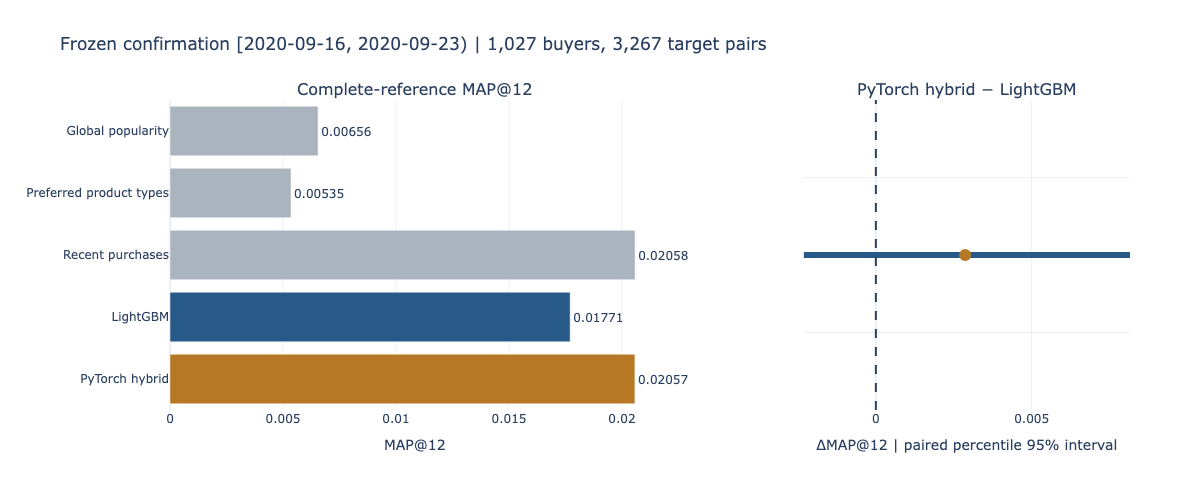

The interval includes zero: no clear paired advantage or equivalence is established.
Validation-selected method: lightgbm_leaves_63_min_20


In [6]:
method_labels = {
    "recent_popularity_7d": "Global popularity",
    "preferred_product_types": "Preferred product types",
    "recent_purchases_180d": "Recent purchases",
    "lightgbm_leaves_63_min_20": "LightGBM",
    "pytorch_hybrid": "PyTorch hybrid",
}
fig = make_subplots(
    rows=1, cols=2, column_widths=[0.6, 0.4], horizontal_spacing=0.15,
    subplot_titles=("Complete-reference MAP@12", "PyTorch hybrid − LightGBM"),
)
fig.add_trace(go.Bar(
    x=confirmation_comparison["map_at_k"],
    y=confirmation_comparison["method"].map(method_labels),
    orientation="h", marker_color=["#AAB4BF"] * 3 + ["#285A89", "#B67824"],
    texttemplate="%{x:.5f}", textposition="outside", cliponaxis=False,
), row=1, col=1)
fig.add_trace(go.Scatter(
    x=[contrast["ci_lower"], contrast["ci_upper"]], y=[0, 0], mode="lines",
    line={"width": 6, "color": "#285A89"},
), row=1, col=2)
fig.add_trace(go.Scatter(
    x=[contrast["observed"]], y=[0], mode="markers",
    marker={"size": 12, "color": "#B67824"},
), row=1, col=2)
fig.add_vline(x=0, line_dash="dash", row=1, col=2)
fig.update_yaxes(autorange="reversed", row=1, col=1)
fig.update_yaxes(showticklabels=False, range=[-1, 1], row=1, col=2)
fig.update_xaxes(title_text="MAP@12", rangemode="tozero", row=1, col=1)
fig.update_xaxes(title_text="ΔMAP@12 | paired percentile 95% interval", row=1, col=2)
fig.update_layout(
    template="plotly_white", showlegend=False, width=1200, height=500,
    margin={"l": 170, "r": 70, "t": 100, "b": 90},
    title=("Frozen confirmation [2020-09-16, 2020-09-23)"
           f" | {confirmation_report['target_buyers']:,} buyers"
           f", {confirmation_report['target_pairs']:,} target pairs"),
)
fig.write_html(str(confirmation_directory / "comparison.html"))
fig.write_image(str(confirmation_directory / "comparison.png"))
fig.show(renderer="plotly_mimetype+png", config={"displaylogo": False})

lower, upper = float(contrast["ci_lower"]), float(contrast["ci_upper"])
if lower > 0:
    interpretation = "The paired interval favors PyTorch hybrid for these fitted systems and this week."
elif upper < 0:
    interpretation = "The paired interval favors LightGBM for these fitted systems and this week."
else:
    interpretation = "The interval includes zero: no clear paired advantage or equivalence is established."
print(interpretation)
print("Validation-selected method:", confirmation_spec["validation_selected_method"])

In [7]:
import mlflow

os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
mlflow.set_tracking_uri((PROJECT_ROOT / "mlruns").as_uri())
mlflow.set_experiment("atelier-ai-weekly-v1")

manifest_sha256 = file_sha256(result_path)
tracking_path = confirmation_directory / "mlflow.json"
tracking_receipt = (
    json.loads(tracking_path.read_text())
    if tracking_path.exists() else None
)

if tracking_receipt:
    assert tracking_receipt["manifest_sha256"] == manifest_sha256

if tracking_receipt is None or tracking_receipt["status"] != "complete":
    with mlflow.start_run(
        run_id=tracking_receipt["run_id"] if tracking_receipt else None,
        run_name="lightgbm_pytorch_final_confirmation",
    ) as tracked_run:
        tracking_receipt = {
            "run_id": tracked_run.info.run_id,
            "manifest_sha256": manifest_sha256,
            "status": "logging",
        }
        tracking_path.write_text(
            json.dumps(tracking_receipt, indent=2)
        )

        mlflow.set_tags({
            "evaluation_role": "final_confirmation",
            "confirmation_evaluated": "true",
            "validation_selected_method": confirmation_spec[
                "validation_selected_method"
            ],
            "pytorch_refit_run_id": confirmation_spec["pytorch_mlflow_run_id"],
            "lightgbm_model_sha256": confirmation_spec["lightgbm_model_sha256"],
        })
        mlflow.log_params({
            "start_inclusive": confirmation_spec["start_inclusive"],
            "end_exclusive": confirmation_spec["end_exclusive"],
            "k": confirmation_spec["recommendations_per_recipient"],
            "bootstrap_resamples": confirmation_spec["bootstrap"]["resamples"],
            "bootstrap_seed": confirmation_spec["bootstrap"]["seed"],
            "bootstrap_paired": True,
            "bootstrap_confidence_level": 0.95,
        })

        for row in confirmation_comparison.to_dict("records"):
            mlflow.log_metrics({
                f"{row['method']}/{metric}": float(row[metric])
                for metric in [
                    "map_at_k", "recall_at_k", "ndcg_at_k",
                    "candidate_coverage", "catalogue_coverage",
                    "mean_recommended_product_groups",
                ]
            }, synchronous=True)

        mlflow.log_metrics({
            key: float(confirmation_report[key])
            for key in [
                "recipients", "source_purchase_rows",
                "target_pairs", "target_buyers", "excluded_nonbuyers",
                "delta_map_at_12", "delta_map_ci_lower", "delta_map_ci_upper",
            ]
        }, synchronous=True)

        for name in [
            *confirmation_report["files_sha256"],
            "protocol.json", "manifest.json",
            "comparison.html", "comparison.png",
        ]:
            mlflow.log_artifact(
                str(confirmation_directory / name),
                artifact_path="confirmation",
            )

    tracking_receipt["status"] = "complete"
    tracking_path.write_text(json.dumps(tracking_receipt, indent=2))

print("Confirmation MLflow run:", tracking_receipt["run_id"])
print("Logging status:", tracking_receipt["status"])

Confirmation MLflow run: 88fc1a0580a944acb65aec96a6da8e1f
Logging status: complete


## Recorded conclusion

All 20,000 recipients receive twelve distinct articles. Complete-reference
metrics cover 1,027 buyers and all 3,267 customer–article targets; 18,973
nonbuyers (94.865%) are excluded from target-based means.

Recent purchases has the highest MAP@12 point estimate (0.020584), followed
by PyTorch hybrid (0.020575) and LightGBM (0.017709). The declared PyTorch
hybrid minus LightGBM delta is 0.002866; its paired percentile 95% interval
[-0.002320, 0.008160] crosses zero. This establishes neither superiority nor
equivalence. PyTorch's higher descriptive Recall/NDCG does not change the
primary MAP selection rule; no baseline-versus-PyTorch paired test is reported.

The hybrid uses neural scores for 2,406 recipients and the fixed recent-purchases
fallback for 17,594. These results describe the complete hybrid system.
No final-week retuning or serving replacement follows. The API/UI still use
the historical LightGBM V1 bundle. See `docs/pytorch_results.md` for artifact
identities, the completed MLflow run and reproducibility limits.
